# Review 2: consolidated comparison of all ten classifiers
The guidelines require all ten algorithms on a common held-out split. This notebook reruns the five
Part A baselines using exactly the same preparation and split as Part B. These are **new comparable
runs**, not copied Review 1 scores. Part A uses fixed baseline settings; Part B includes baseline and tuned settings.

Run notebooks 06–10 first. Select the deployment model using training CV macro F1 only.
The test table is descriptive; no hyperparameters or winner are chosen using test scores.


In [1]:
from pathlib import Path
import sys, os, warnings, json
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if not (ROOT / 'src').exists():
    raise RuntimeError('Open this notebook inside the extracted project/notebooks folder.')
sys.path.insert(0, str(ROOT))
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
%matplotlib inline
sns.set_theme(style='whitegrid', palette='colorblind')
from sklearn.base import clone
from sklearn.model_selection import cross_validate, GridSearchCV
from src.classification import *
raw, df, train, test = load_data()
X_train, y_train = train[RAW_FEATURES], train[TARGET]
X_test, y_test = test[RAW_FEATURES], test[TARGET]
display(pd.DataFrame({'Raw': raw[TARGET].value_counts(), 'Cleaned': df[TARGET].value_counts(),
                      'Train': y_train.value_counts(), 'Test': y_test.value_counts()}))
display(df.dtypes.to_frame('dtype').astype(str))
print('Removed exact duplicate rows:', len(raw) - len(df))
assert not df.duplicated().any()
assert set(train.index).isdisjoint(test.index)


Removed exact duplicate rows: 0


,Raw,Cleaned,Train,Test
transmission,,,,
Automatic,1250,1250,1000,250
Manual,1250,1250,1000,250


,dtype
brand,object
model,object
year,int64
price_gbp,int64
mileage_miles,int64
fuel_type,object
tax_gbp,int64
mpg_uk,float64
engine_size_l,float64
transmission,string


In [2]:
import joblib
rows=[]
for slug, (name, estimator) in part_a_models().items():
    model=build_pipeline(estimator)
    cv=cross_validate(model,X_train,y_train,cv=CV,scoring=SCORING,n_jobs=1,error_score='raise')
    model.fit(X_train,y_train)
    row={'Slug':slug,'Model':name,'Part':'A rerun','Stage':'Baseline',**metrics(model,X_test,y_test),
         'CV_macro_F1':cv['test_f1_macro'].mean(),'CV_macro_F1_std':cv['test_f1_macro'].std()}
    rows.append(row)
    joblib.dump(model,ROOT/'models'/f'{slug}_before.joblib',compress=3)
    print('Completed:',name)
part_a=pd.DataFrame(rows)
part_a.to_csv(ROOT/'results/part_a_rerun.csv',index=False)
display(part_a.round(4))


Completed: Logistic Regression
Completed: KNN
Completed: Gaussian Naive Bayes
Completed: Decision Tree
Completed: SVC


,Slug,Model,Part,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std
0,logistic_regression,Logistic Regression,A rerun,Baseline,0.828,0.8322,0.828,0.8275,0.8275,0.828,0.8694,0.772,0.9227,0.9298,0.8358,0.0185
1,knn,KNN,A rerun,Baseline,0.818,0.8195,0.818,0.8178,0.8178,0.818,0.8412,0.784,0.8924,0.8768,0.8264,0.0210
2,naive_bayes,Gaussian Naive Bayes,A rerun,Baseline,0.670,0.7807,0.670,0.6339,0.6339,0.670,0.9570,0.356,0.8449,0.8569,0.6770,0.0206
3,decision_tree,Decision Tree,A rerun,Baseline,0.828,0.8285,0.828,0.8279,0.8279,0.828,0.8417,0.808,0.8280,0.7761,0.8090,0.0136
4,svc,SVC,A rerun,Baseline,0.836,0.8391,0.836,0.8356,0.8356,0.836,0.8717,0.788,0.9229,0.9328,0.8298,0.0211


All five Part B models AFTER tuning (ordered by training CV macro F1):
After minus before:
Deployment selection: {'slug': 'random_forest', 'name': 'Random Forest', 'stage': 'Before tuning', 'model_file': 'random_forest_before.joblib', 'cv_macro_f1': 0.8549557420459012, 'selection_basis': 'Highest five-fold training CV macro F1; test metrics not used'}


,Model,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std,Slug,Part
1,Random Forest,After tuning,0.868,0.8692,0.868,0.8679,0.8679,0.868,0.8898,0.840,0.9347,0.9403,0.8550,0.0147,random_forest,B
7,Bagging,After tuning,0.862,0.8625,0.862,0.8620,0.8620,0.862,0.8755,0.844,0.9336,0.9344,0.8489,0.0258,bagging,B
9,MLP,After tuning,0.846,0.8469,0.846,0.8459,0.8459,0.846,0.8650,0.820,0.9273,0.9344,0.8449,0.0180,mlp,B
5,Gradient Boosting,After tuning,0.858,0.8605,0.858,0.8577,0.8577,0.858,0.8908,0.816,0.9268,0.9354,0.8368,0.0200,gradient_boosting,B
3,AdaBoost,After tuning,0.806,0.8129,0.806,0.8049,0.8049,0.806,0.8592,0.732,0.9005,0.9048,0.8099,0.0257,adaboost,B


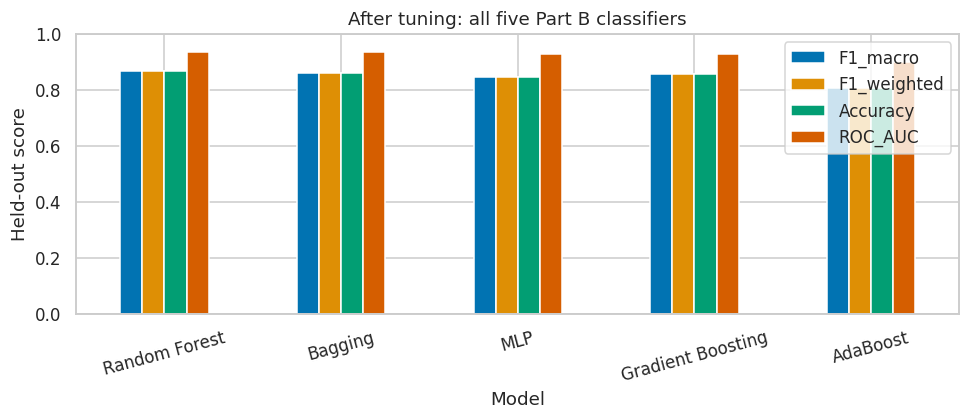

,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,ROC_AUC,CV_macro_F1
0,Random Forest,0.000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000
1,AdaBoost,-0.008,-0.0026,-0.008,-0.0089,-0.0089,0.0027,0.0047
2,Gradient Boosting,0.000,-0.0005,0.000,0.0001,0.0001,-0.0029,0.0050
3,Bagging,0.020,0.0204,0.020,0.0200,0.0200,0.0169,0.0135
4,MLP,0.000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000


,Slug,Model,Part,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std
5,random_forest,Random Forest,B,Before tuning,0.868,0.8692,0.868,0.8679,0.8679,0.868,0.8898,0.840,0.9347,0.9403,0.8550,0.0147
12,bagging,Bagging,B,After tuning,0.862,0.8625,0.862,0.8620,0.8620,0.862,0.8755,0.844,0.9336,0.9344,0.8489,0.0258
13,mlp,MLP,B,Before tuning,0.846,0.8469,0.846,0.8459,0.8459,0.846,0.8650,0.820,0.9273,0.9344,0.8449,0.0180
10,gradient_boosting,Gradient Boosting,B,After tuning,0.858,0.8605,0.858,0.8577,0.8577,0.858,0.8908,0.816,0.9268,0.9354,0.8368,0.0200
0,logistic_regression,Logistic Regression,A rerun,Baseline,0.828,0.8322,0.828,0.8275,0.8275,0.828,0.8694,0.772,0.9227,0.9298,0.8358,0.0185
4,svc,SVC,A rerun,Baseline,0.836,0.8391,0.836,0.8356,0.8356,0.836,0.8717,0.788,0.9229,0.9328,0.8298,0.0211
1,knn,KNN,A rerun,Baseline,0.818,0.8195,0.818,0.8178,0.8178,0.818,0.8412,0.784,0.8924,0.8768,0.8264,0.0210
8,adaboost,AdaBoost,B,After tuning,0.806,0.8129,0.806,0.8049,0.8049,0.806,0.8592,0.732,0.9005,0.9048,0.8099,0.0257
3,decision_tree,Decision Tree,A rerun,Baseline,0.828,0.8285,0.828,0.8279,0.8279,0.828,0.8417,0.808,0.8280,0.7761,0.8090,0.0136
2,naive_bayes,Gaussian Naive Bayes,A rerun,Baseline,0.670,0.7807,0.670,0.6339,0.6339,0.670,0.9570,0.356,0.8449,0.8569,0.6770,0.0206


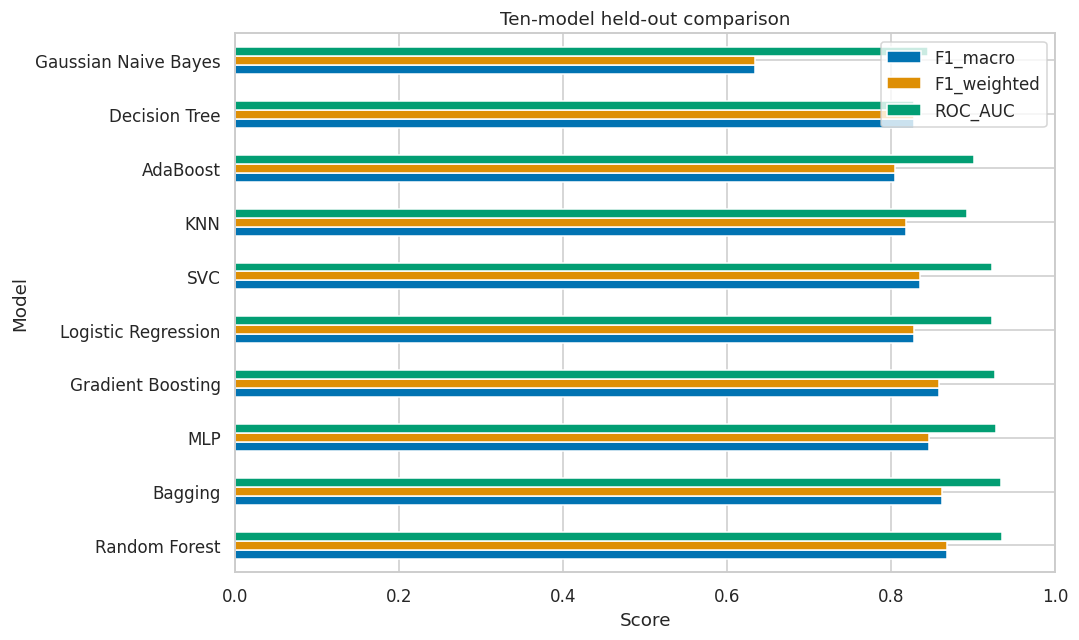

In [3]:
part_b=[]
for slug in configurations():
    path=ROOT/'results'/slug/'comparison.csv'
    if not path.exists(): raise FileNotFoundError(f'Run the {slug} notebook first.')
    t=pd.read_csv(path);t['Slug']=slug;t['Part']='B'
    part_b.append(t)
part_b=pd.concat(part_b,ignore_index=True)
all_runs=pd.concat([part_a,part_b],ignore_index=True)
all_runs.to_csv(ROOT/'results/all_classification_runs.csv',index=False)
part_b.to_csv(ROOT/'results/part_b_before_after.csv',index=False)
after=part_b[part_b.Stage=='After tuning'].sort_values('CV_macro_F1',ascending=False)
after.to_csv(ROOT/'results/after_tuning_comparison.csv',index=False)
print('All five Part B models AFTER tuning (ordered by training CV macro F1):')
display(after.round(4))
fig,ax=plt.subplots(figsize=(9,4))
after.set_index('Model')[['F1_macro','F1_weighted','Accuracy','ROC_AUC']].plot.bar(ax=ax,ylim=(0,1))
ax.set(title='After tuning: all five Part B classifiers',ylabel='Held-out score',xlabel='Model')
plt.xticks(rotation=15);plt.tight_layout();plt.savefig(ROOT/'results/after_tuning_comparison.png',dpi=130);plt.show()
delta_rows=[]
for slug,g in part_b.groupby('Slug',sort=False):
    before=g[g.Stage=='Before tuning'].iloc[0];tuned_row=g[g.Stage=='After tuning'].iloc[0]
    cols=['Accuracy','Precision_weighted','Recall_weighted','F1_weighted','F1_macro','ROC_AUC','CV_macro_F1']
    delta_rows.append({'Model':before.Model,**{col:float(tuned_row[col]-before[col]) for col in cols}})
deltas=pd.DataFrame(delta_rows)
deltas.to_csv(ROOT/'results/tuning_deltas.csv',index=False)
print('After minus before:');display(deltas.round(4))

# Choose each model's baseline/tuned version and the global winner on training CV only.
selected=all_runs.sort_values('CV_macro_F1',ascending=False,kind='stable').drop_duplicates('Slug')
selected.to_csv(ROOT/'results/ten_model_comparison.csv',index=False)
display(selected.round(4))
winner=selected.iloc[0]
suffix='after' if winner.Stage=='After tuning' else 'before'
selection={'slug':winner.Slug,'name':winner.Model,'stage':winner.Stage,
           'model_file':f'{winner.Slug}_{suffix}.joblib','cv_macro_f1':float(winner.CV_macro_F1),
           'selection_basis':'Highest five-fold training CV macro F1; test metrics not used'}
(ROOT/'results/selected_model.json').write_text(json.dumps(selection,indent=2))
print('Deployment selection:',selection)
ax=selected.set_index('Model')[['F1_macro','F1_weighted','ROC_AUC']].plot.barh(figsize=(10,6),xlim=(0,1))
ax.set(title='Ten-model held-out comparison',xlabel='Score',ylabel='Model')
plt.tight_layout();plt.savefig(ROOT/'results/ten_model_comparison.png',dpi=130);plt.show()


## Complete your review discussion
Explain why the selected model was chosen using CV, compare its held-out performance to alternatives,
and discuss the Automatic-class precision/recall tradeoff. If tuning did not improve a metric, report
that outcome rather than changing the test split. Five-fold CV covers all ten models, exceeding the
two-model minimum. Review 1 regression is outside this package because its notebook was not supplied.
